# When there is no extremal metric: an unstable orbifold

Notebook 02 solved for an extremal metric that exists. Here the opposite: a polygon that is relatively K-unstable, so Abreu's equation S(u) = A_ext has no solution. What does the numerical method do, and where do the approximating metrics degenerate?

**Theory.** The solver minimizes Donaldson's convex functional F(u) = −∫ log det Hess u dμ + 2 L_A(u) over potentials u = u_G + h with h a polynomial of degree ≤ d. If L_A(f) < 0 for some convex f, F is unbounded below on all convex u; on degree-d polynomials it may still be bounded, and the instability shows up in what the best degree-d metrics look like.

**Where to expect degeneration.** In 2D the barrier −∫ log det Hess u is weak: it stays finite even if Hess u degenerates along a curve, so nothing in F forbids degenerate minimizers. Where can curvature concentrate? Not in the interior: a blow-up limit at an interior point would be a complete, non-flat toric Kähler metric with s ≥ 0 and a free torus action, and such metrics are flat (B. Weber, *Analytic classification of toric Kähler instanton metrics in dimension 4*, J. Geom. 2023, arXiv:2104.00892, Thm 1.1 and Cor. 1.2). At an edge the limit lives on a half-plane, where non-flat scalar-flat metrics exist. So degeneration should happen along edges.

**Why an orbifold.** The smooth unstable examples (Wang–Zhou's nonagon) are extremely elongated, beyond the reach of global polynomials. Labelled polygons give compact unstable examples: by Apostolov–Calderbank–Gauduchon (*Ambitoric geometry II*, Ann. Sci. ENS 2015, Prop. 6), every quadrilateral that is not a parallelogram becomes unstable for suitable labels. (The instability claims in Legendre's earlier *Toric geometry of convex quadrilaterals* are incorrect, as ACG point out: equipoised quadrilaterals are always stable.) An edge with label m has defining function ℓ = m(⟨u, x⟩ − λ), which enters Guillemin's potential ½ Σ ℓ log ℓ, and boundary measure σ = (lattice length)/m. An integer m > 1 means cone angle 2π/m along that divisor.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from extremal import Polygon, viz
from extremal.quadrature import polygon_quadrature
from extremal.solver import ExtremalSolver
from extremal.stability import crease_search

## 1. A family of labelled quadrilaterals

Q_k has vertices (0,0), (5,0), (4,1), (0,2) and labels (1, k, k, k): the bottom edge has label 1, the other three label k. Labels only matter up to a common factor, so equivalently the bottom edge has label 1/k. Q_k is an orbifold even for k = 1: the vertex (4, 1) is not smooth.

### Q_12

- vertices: (0, 0), (5, 0), (4, 1), (0, 2)
- Delzant: no (singular vertices [2, 3])
- labels: 1, 12, 12, 12 (an orbifold if integers > 1)
- area μ(P) = 13/2,  boundary σ(∂P) = 16/3
- average scalar curvature Ŝ = 32/39
- A_ext = -2958*x/23761 - 60935*y/23761 + 70647/23761
- Futaki (F(x), F(y)) = (2351/936, -425/117)

| edge | normal u | λ | lattice length | label | σ(edge) |
|---|---|---|---|---|---|
| 0 | (0, 1) | 0 | 5 | 1 | 5 |
| 1 | (-1, -1) | -5 | 1 | 12 | 1/12 |
| 2 | (-1, -4) | -8 | 1 | 12 | 1/12 |
| 3 | (1, 0) | 0 | 2 | 12 | 1/6 |

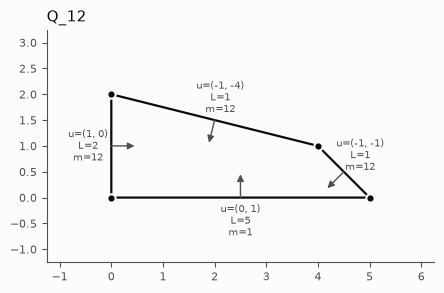

In [2]:
V = [(0, 0), (5, 0), (4, 1), (0, 2)]
Q = lambda k: Polygon(V, labels=(1, k, k, k), name=f'Q_{k}')
EDGE = {0: 'e0 bottom', 1: 'e1 right', 2: 'e2 top', 3: 'e3 left'}
display(Markdown(Q(12).report()))
viz.plot_polygon(Q(12), vertex_labels=False);

## 2. Where it becomes unstable

The crease-stability margin min L(f)/∫_∂P f dσ over all simple creases (notebook 01, §5), as a function of k. Negative means unstable; for those k there is an exact rational certificate.

k =    1: margin +0.1610 at θ =  60.2°   
k =    2: margin +0.0879 at θ =  56.9°   
k =    3: margin +0.0530 at θ =  55.2°   
k =    4: margin +0.0323 at θ =  54.2°   
k =    5: margin +0.0185 at θ =  53.4°   
k =    6: margin +0.0016 at θ =  58.8°   
k =  6.5: margin -0.0219 at θ =  59.6°   certificate max(0, 17x + 29y + -397506/5711),  L = -0.2303
k =    7: margin -0.0477 at θ =  60.1°   certificate max(0, 27x + 47y + -842829/7583),  L = -0.6856
k =  7.5: margin -0.0752 at θ =  60.4°   certificate max(0, 17x + 30y + -620022/8833),  L = -0.6028
k =    8: margin -0.1040 at θ =  60.7°   certificate max(0, 32x + 57y + -143431/1084),  L = -1.4181
k =    9: margin -0.1647 at θ =  61.0°   certificate max(0, 5x + 9y + -88549/4284),  L = -0.2978
k =   10: margin -0.2283 at θ =  61.1°   certificate max(0, 27x + 49y + -1092403/9784),  L = -1.9335
k =   11: margin -0.2940 at θ =  61.2°   certificate max(0, 17x + 31y + -365084/5197),  L = -1.3904
k =   12: margin -0.3614 at θ =  61.3°   certifica

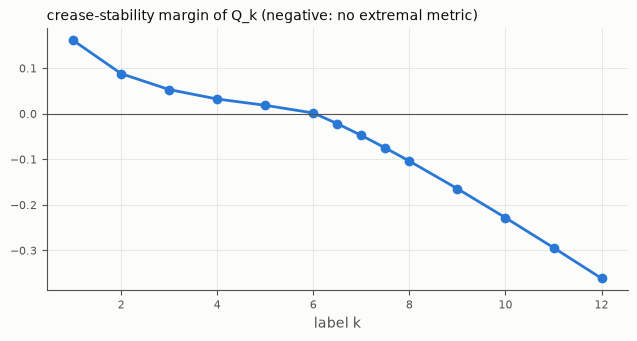

In [ ]:
from fractions import Fraction
ks = [1, 2, 3, 4, 5, 6, 6.5, 7, 7.5, 8, 9, 10, 11, 12]
searches = {k: crease_search(Q(k if k == int(k) else Fraction(str(k)))) for k in ks}
for k, r in searches.items():
    c = r.certificate
    cert = f'certificate max(0, {c[0]}x + {c[1]}y + {c[2]}),  L = {float(r.certificate_value):.4f}' if r.unstable else ''
    print(f'k = {k:>4}: margin {r.best_margin:+.4f} at θ = {np.degrees(r.best_theta):5.1f}°   {cert}')

ax = viz._line_axes(None, figsize=(7.5, 3.4))
ax.plot(ks, [searches[k].best_margin for k in ks], 'o-', color='#2a78d6', lw=2, ms=6)
ax.axhline(0, color=viz.INK_2, lw=0.8)
ax.set_xlabel('label k', color=viz.INK_2)
ax.set_title('crease-stability margin of Q_k (negative means no extremal metric)', loc='left', fontsize=10, color=viz.INK);

The certified destabilizing crease for k = 12. It cuts off the corner between e1 and e2, where two heavily labelled edges meet: large labels make edges light in σ, so the boundary term of L is small there.

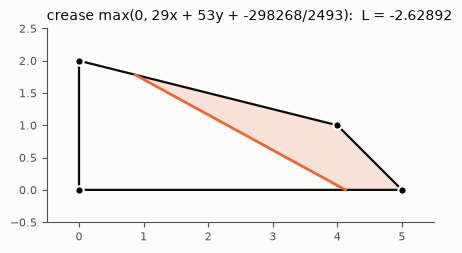

In [4]:
cert = searches[12].certificate
viz.plot_crease(Q(12), *cert);

## 3. Stable versus unstable: does the answer depend on the discretization?

The solver only enforces convexity of u at its quadrature nodes. When an extremal metric exists that is harmless. When it doesn't, the minimizer is pushed towards degenerating, and the result depends on how finely convexity is enforced. Below: d = 10, with nodes packed towards the edges (`quad_scheme='edges'`, grading g), for several node counts q. `non-convex` counts points of a fine independent test set where Hess u is not positive definite.

In [5]:
print(f"{'':6} {'q':>4} {'g':>2} {'F_min':>11} {'Newton':>7} {'non-convex':>11}")
for k in (4, 12):
    for q, g in ((50, 2), (80, 2), (50, 3), (80, 3)):
        r = ExtremalSolver(Q(k), degree=10, quad_order=q, quad_scheme='edges', grading=g).solve(max_iter=500)
        cv = r.convexity()
        print(f"Q_{k:<4} {q:>4} {g:>2} {r.history[-1]['F']:>11.4f} {len(r.history):>7} {cv['non_convex']:>5}/{cv['points']}")

          q  g       F_min  Newton  non-convex
Q_4      50  2     -8.5108       9     0/57600
Q_4      80  2     -8.5108       9     0/57600
Q_4      50  3     -8.5108       9     0/57600
Q_4      80  3     -8.5108      10     0/57600
Q_12     50  2   -446.8713      43   141/57600
Q_12     80  2   -503.2379      67    76/57600
Q_12     50  3   -496.0310      56   127/57600
Q_12     80  3   -348.0545      77    77/57600


Q₄ gives F_min = −8.5108 every time, with no non-convex points: a genuine minimum, the extremal metric. For Q₁₂ the value moves with the discretization and some points are always non-convex: the best degree-d metric is degenerate, and the numerics only approximate how degenerate. (Since the degree-d spaces are nested, the true minimum over convex u can only decrease with d; the computed values for Q₁₂ need not, so they should not be read as a trend.)

For the stable Q₄, the solution converges as d grows:

d =  6:  9 Newton steps,  F = -8.48435389,  S − A_ext: sup 1.6e+01, L² 7.4e-01
d = 10:  9 Newton steps,  F = -8.51076601,  S − A_ext: sup 2.0e+00, L² 2.1e-01
d = 14:  9 Newton steps,  F = -8.51130659,  S − A_ext: sup 7.5e-01, L² 6.4e-02
d = 18:  9 Newton steps,  F = -8.51133552,  S − A_ext: sup 2.7e-01, L² 2.2e-02
d = 22:  10 Newton steps,  F = -8.51133677,  S − A_ext: sup 1.1e-01, L² 6.2e-03


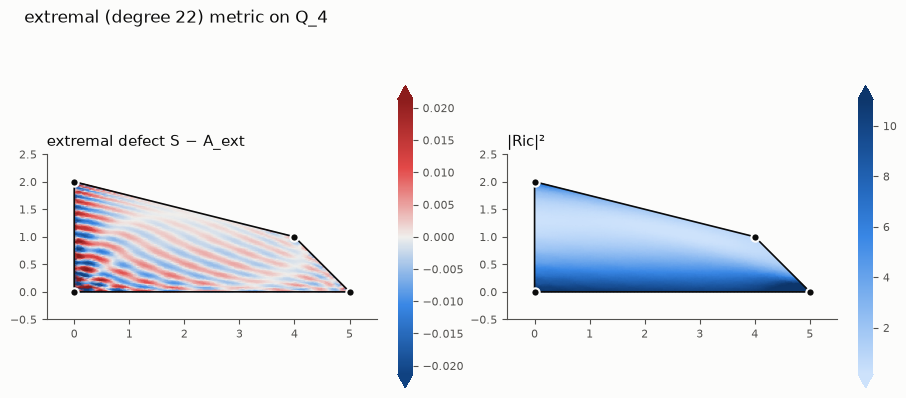

In [6]:
for dd in (6, 10, 14, 18, 22):
    r = ExtremalSolver(Q(4), degree=dd).solve()
    D = r.defect(order=30)
    print(f'd = {dd:>2}:  {len(r.history)} Newton steps,  F = {r.history[-1]["F"]:.8f},  S − A_ext: sup {D["sup"]:.1e}, L² {D["L2"]:.1e}')
viz.plot_fields(r.metric, names=('S - A_ext', '|Ric|^2'), resolution=80);

## 4. Which edges degenerate

Near edge i, Hess u ≈ (mᵢ/2ℓᵢ) n nᵀ + B with B bounded, so Hess u stays positive definite near the edge exactly when τᵀBτ > 0 on it (τ the edge direction). That is strict convexity of u restricted to the edge: the toric potential of the metric on that divisor. `edge_convexity` reports τᵀ(Hess u)τ along each edge, divided by its value for Guillemin's metric (so 1 for h = 0); a value at or below 0 means the divisor's metric degenerates.

Profiles along each edge at d = 12, stable Q₄ (left) and unstable Q₁₂ (right):

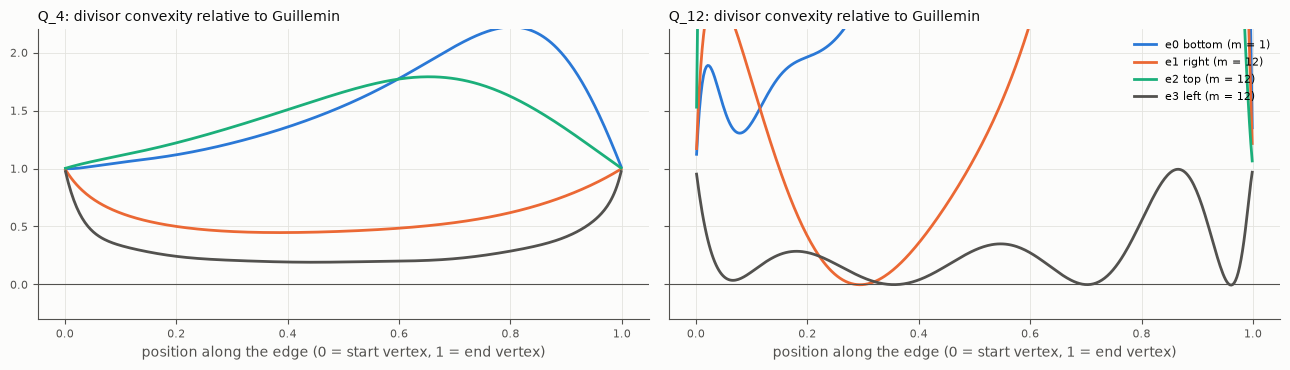

In [7]:
sols = {k: ExtremalSolver(Q(k), degree=12, quad_order=96, quad_scheme='edges', grading=2).solve(max_iter=500) for k in (4, 12)}
colors = ['#2a78d6', '#eb6834', '#1baf7a', '#52514e']
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
fig.patch.set_facecolor(viz.SURFACE)
for ax, k in zip(axes, (4, 12)):
    viz._line_axes(ax)
    for e, col in zip(sols[k].edge_convexity(), colors):
        ax.plot(e['t'], e['profile'], color=col, lw=2, label=f"{EDGE[e['edge']]} (m = {e['label']})")
    ax.axhline(0, color=viz.INK_2, lw=0.8)
    ax.set_xlabel('position along the edge (0 = start vertex, 1 = end vertex)', color=viz.INK_2)
    ax.set_title(f'Q_{k}: divisor convexity relative to Guillemin', loc='left', fontsize=10, color=viz.INK)
axes[0].set_ylim(-0.3, 2.2)
axes[1].legend(frameon=False, fontsize=8, loc='upper right')
fig.tight_layout()

The minimum of that ratio on each edge, as the degree grows (Q₁₂, edge-packed nodes):

In [8]:
print(f"{'d':>3}  " + '  '.join(f'{EDGE[i]:>12}' for i in range(4)))
for dd in (6, 8, 10, 12, 14):
    r = sols[12] if dd == 12 else ExtremalSolver(Q(12), degree=dd, quad_order=8 * dd, quad_scheme='edges', grading=2).solve(max_iter=500)
    print(f'{dd:>3}  ' + '  '.join(f"{e['ratio']:>+12.2e}" for e in r.edge_convexity()))
print(f"\nQ_4, d = 12:  " + '  '.join(f"{e['ratio']:>+12.2e}" for e in sols[4].edge_convexity()))

  d     e0 bottom      e1 right        e2 top       e3 left
  6     +1.07e+00     +1.11e+00     +1.20e+00     -1.04e-02
  8     +1.04e+00     -1.21e-03     +1.75e-01     -3.58e-04
 10     +1.29e+00     -1.85e-03     +1.19e+00     -2.03e-02
 12     +1.12e+00     -2.24e-03     +1.07e+00     -5.50e-03
 14     +1.18e+00     -1.31e-03     +1.96e-02     -2.51e-03

Q_4, d = 12:     +9.98e-01     +4.48e-01     +1.00e+00     +1.92e-01


The left edge e3 loses convexity at every degree, and the right edge e1 from d = 8 on (both label 12). The bottom edge e0 (label 1) stays healthy throughout; the top edge e2 (label 12) mostly does, but dips at d = 8 and d = 14. How negative the ratio gets depends on the discretization. For Q₄ all four stay comfortably positive.

Note the shape of the e3 profile for Q₁₂: it touches 0 at several separate points. That is what one would expect if the infimum wants the whole divisor to collapse: a polynomial can only make the ratio vanish at finitely many points, so it does so repeatedly.

## 5. Curvature

|Ric|² of the d = 12 metrics. The degeneration lives in a thin layer along the edges, too thin for a heat map on a uniform grid, so first a heat map of log₁₀|Ric|² for the overall picture (Q₁₂ also shows oscillating ridges in the interior, of much smaller size, presumably the polynomial straining against the degenerate boundary), then |Ric|² along a line running into the left edge e3 at the point where it degenerates most, against the distance to that edge (log–log). Points where Hess u is not positive definite are left out. Very close to ∂P (closer than about 10⁻⁵) the fourth-derivative evaluation of curvature loses digits even for a smooth metric, so the plot stops there.

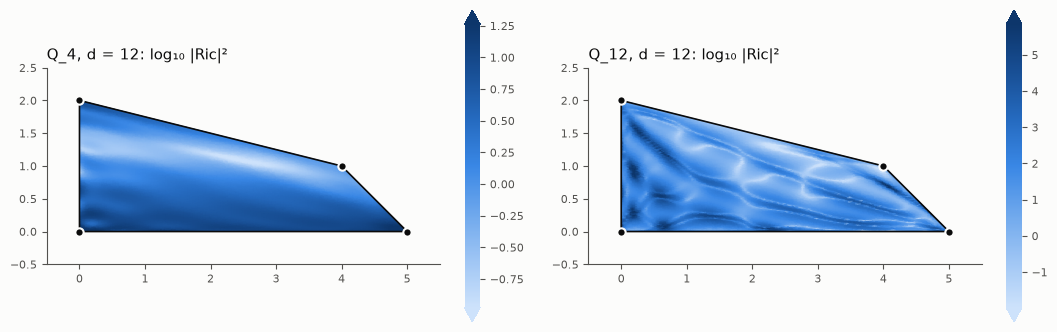

In [9]:
def log_ricci(metric):
    def fn(x, y):
        R = metric.ricci_norm_sq(x, y)
        ok = metric.min_hessian_eigenvalue(x, y) > 0
        return np.where(ok, np.log10(R), np.nan)
    return fn

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
fig.patch.set_facecolor(viz.SURFACE)
for ax, k in zip(axes, (4, 12)):
    viz.plot_function(Q(k), log_ricci(sols[k].metric), ax=ax, resolution=120, clip_percentile=99.5,
                      label=f'Q_{k}, d = 12: log₁₀ |Ric|²')
fig.tight_layout()

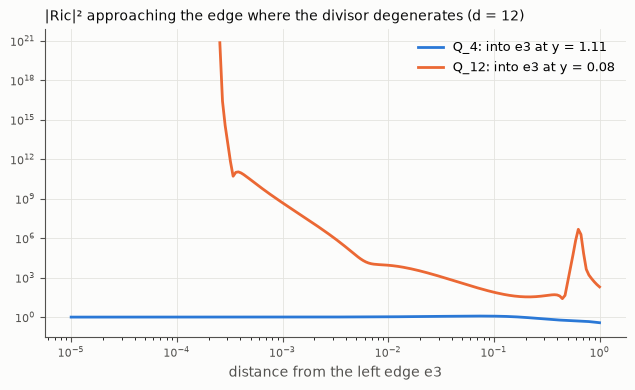

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 4))
fig.patch.set_facecolor(viz.SURFACE)
viz._line_axes(ax)
dist = np.logspace(-5, 0, 200)
for k, col in ((4, '#2a78d6'), (12, '#eb6834')):
    e3 = sols[k].edge_convexity()[3]
    x0, y0 = e3['at']
    R = sols[k].metric.ricci_norm_sq(x0 + dist, np.full_like(dist, y0))   # e3 is x = 0, inward normal (1, 0)
    ok = sols[k].metric.min_hessian_eigenvalue(x0 + dist, np.full_like(dist, y0)) > 0
    ax.loglog(dist[ok], R[ok], color=col, lw=2, label=f'Q_{k}: into e3 at y = {y0:.2f}')
ax.set_xlabel('distance from the left edge e3', color=viz.INK_2)
ax.set_title('|Ric|² approaching the edge where the divisor degenerates (d = 12)', loc='left', fontsize=10, color=viz.INK)
ax.legend(frameon=False, fontsize=9);

## 6. The optimal destabilizer

The crease in §2 minimizes L(f)/∫_∂P f dσ, the uniform-stability normalization. A different normalization has a geometric meaning (Donaldson, *Lower bounds on the Calabi functional*, JDG 2005; Székelyhidi, *Optimal test-configurations for toric varieties*, JDG 2008): for every toric metric,

  ‖S − A_ext‖_{L²(μ)} ≥ sup_f −L_A(f)/‖f‖_{L²(μ)}   (f convex, taken modulo affine functions),

and the sup is attained by the minimizer f* of the convex functional W(f) = L_A(f) + ½‖f‖² (then L_A(f*) = −‖f*‖² and the sup is ‖f*‖).

**Restricted to simple creases** f = c·max(0, ℓ) + affine: the optimal c and affine part make f = c·φ⊥ (φ = max(0, ℓ), φ⊥ its L²-projection off the affine functions) with c = −L_A(φ)/‖φ⊥‖², and the line ℓ = 0 must be a critical point of −L_A(φ)/‖φ⊥‖. Varying the crease line, the stationarity conditions say that **on each piece P_i, A − f* is the extremal affine function A_i of P_i**, computed with the measure σ on ∂P ∩ P_i and *zero* measure on the crease. Since f* is continuous, A_1 = A_2 along the crease.

**Exactly.** Write the line as x + m y = s. On each cell of the line arrangement (a pair of edges crossed) every quantity is a rational function of (m, s), so the critical points are the common zeros of two polynomials with rational coefficients: a resultant gives a polynomial in m, whose real roots are isolated exactly, and the same for s. `crease_exact.optimal_crease` does this; `crease_exact.crease_minimum` does the same for the boundary-normalized ratio of §2 (which `crease_search` now uses by default).

In [11]:
from extremal.crease_exact import crease_minimum, optimal_crease, optimality_scan
opt = optimal_crease(Q(12))
bmin = crease_minimum(Q(12))
print(opt)
print()
print('boundary-normalized minimum (§2):', bmin.crease)
print('minimal polynomial of the optimal slope m:')
print(' ', opt.crease.minimal_polynomial_m().as_expr())

optimal simple crease: x + 1.65238288201646·y = 4.13800009076811  (θ = 58.818235°, edges (0, 2), critical): value 0.164174111374
  ‖f*‖ = 0.16417411137442506876   (lower bound for ‖S − A_ext‖_L²(μ))
  f* = 0.285846031377·max(0, 1.0x + 1.65238288202y − 4.13800009077) + (0.099510632) + (-0.05265273)x + (-0.051400509)y
  minimal polynomial of the slope m: degree 18
  checks: L(f*) + ‖f*‖² = -4.18e-53,  A − f* vs piece extremal functions: 1.49e-47,  A_1 − A_2 on the crease: 8.85e-49

boundary-normalized minimum (§2): x + 1.82780680643883·y = 4.7499734056205  (θ = 61.316764°, edges (0, 2), critical): value -0.361405161299
minimal polynomial of the optimal slope m:
  7008767128912761223817993456952803328*m**18 - 12710091659622040666110574268305964531712*m**17 - 35297015323001762709922343676353879998464*m**16 + 4976698214503497079959468056740051342589952*m**15 - 39160016616646297549711412193850120451653632*m**14 - 353512498822845151579596700398849389351141376*m**13 + 8843412890335166480597425

The three checks printed above are independent of how the crease was found: L_A(f*) + ‖f*‖² = 0 (the scaling identity), A − f* agrees with the extremal function of each piece, and those two piece functions agree along the crease. All hold to about 50 digits. The two creases are close but different: the normalization matters away from the threshold.

smallest value 8.42e-05 at θ = 59.0° (f*'s crease: 58.82°)


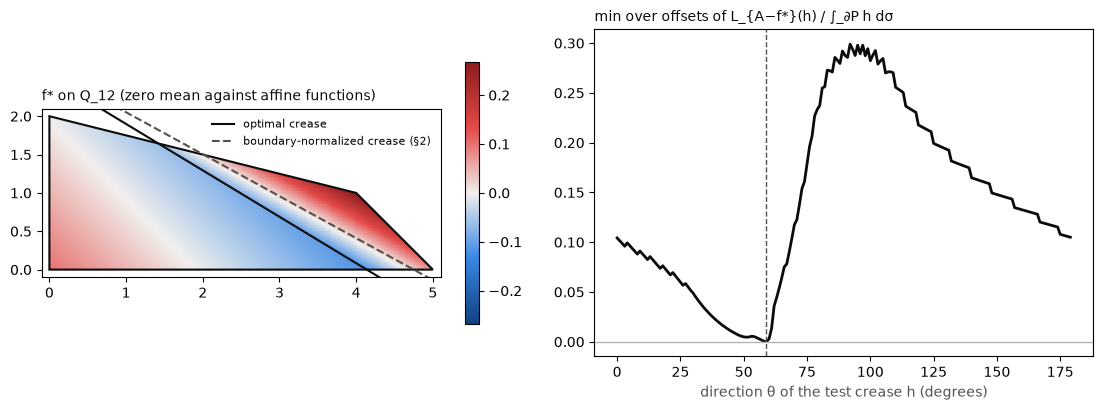

In [12]:
import mpmath
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
P = Q(12)
xs, ys = zip(*[(float(a), float(b)) for a, b in P.vertices])
gx, gy = np.meshgrid(np.linspace(0, 5, 400), np.linspace(0, 2, 200))
inside = np.ones_like(gx, bool)
for e in P.edges:
    inside &= e.normal[0] * gx + e.normal[1] * gy - float(e.constant) >= 0
F = np.where(inside, opt(gx, gy), np.nan)
ax = axes[0]
im = ax.pcolormesh(gx, gy, F, cmap=viz.DIVERGING, vmin=-np.nanmax(np.abs(F)), vmax=np.nanmax(np.abs(F)), shading='auto')
ax.fill(xs + xs[:1], ys + ys[:1], fill=False, color=viz.INK, lw=1.5)
t = np.linspace(-1, 6, 2)
for cr, col, lab in ((opt.crease, viz.INK, 'optimal crease'), (bmin.crease, viz.INK_2, 'boundary-normalized crease (§2)')):
    a, b = (float(v) for v in cr.normal)
    if abs(b) > 1e-12:
        ax.plot(t, (float(cr.s) - a * t) / b, color=col, lw=1.5, ls='-' if col == viz.INK else '--', label=lab)
ax.set_xlim(-0.1, 5.1); ax.set_ylim(-0.1, 2.1); ax.set_aspect('equal')
ax.set_title('f* on Q_12 (zero mean against affine functions)', loc='left', fontsize=10, color=viz.INK)
ax.legend(frameon=False, fontsize=8, loc='upper right')
fig.colorbar(im, ax=ax, shrink=0.8)
scan = optimality_scan(opt, n_angles=180, samples=120)
ax = axes[1]
ax.plot(np.degrees(scan['theta']), scan['margin'], color=viz.INK, lw=2)
ax.axhline(0, color='#b5b4b0', lw=1)
ax.axvline(np.degrees(opt.crease.theta), color=viz.INK_2, lw=1, ls='--')
ax.set_xlabel('direction θ of the test crease h (degrees)', color=viz.INK_2)
ax.set_title('min over offsets of L_{A−f*}(h) / ∫_∂P h dσ', loc='left', fontsize=10, color=viz.INK)
fig.tight_layout()
print(f"smallest value {scan['min']:.2e} at θ = {np.degrees(scan['at']):.1f}° (f*'s crease: {np.degrees(opt.crease.theta):.2f}°)")

**Is f* optimal among all convex functions, not just simple creases?** W is convex, so f* is the global minimizer iff L_{A−f*}(h) = L_A(h) + ∫ f* h dμ ≥ 0 for every convex h. The right panel samples simple creases h: the minimum is ≈ 0, attained in f*'s own direction, and positive elsewhere. For affine A, Wang–Zhou's theorem says simple creases decide such inequalities; A − f* is only piecewise affine, so this is a necessary condition that f* passes, not a proof.

### Along the family P(λ)

Notebook 04: P(λ) = {y ≥ 0, x ≥ 0, x + y ≤ λ, x + 4y ≤ 8}, labels (1, 12, 12, 12), Q_12 = P(5), unstable for λ* ≈ 4.31757 < λ < λ** ≈ 7.90742. At λ* the balanced crease (L = ∂L = 0) has f* = 0.

In [13]:
from fractions import Fraction as Fr
def Pl(lam, k=12):
    yv = (8 - lam) / 3
    return Polygon([(0, 0), (lam, 0), (lam - yv, yv), (0, 2)], labels=(1, k, k, k))
LAM_STAR, LAM_2STAR, THETA_STAR = 4.31756909532834814, 7.90742, 51.948353
lams = [Fr(108, 25), Fr(22, 5), Fr(23, 5), Fr(5), Fr(11, 2), Fr(6), Fr(13, 2), Fr(7), Fr(15, 2), Fr(39, 5), Fr(79, 10)]
rows = []
for lam in lams:
    o, b = optimal_crease(Pl(lam)), crease_minimum(Pl(lam))
    rows.append((float(lam), float(o.norm), np.degrees(o.crease.theta), float(b.value), np.degrees(b.crease.theta),
                 max(float(o.piece_residual), float(o.continuity_residual))))
print('    λ       ‖f*‖      θ_opt     boundary margin   θ_bnd    piece residuals')
for r in rows:
    print(f'{r[0]:6.3f}  {r[1]:.6f}  {r[2]:8.4f}°   {r[3]:+.6f}     {r[4]:8.4f}°   {r[5]:.0e}')

    λ       ‖f*‖      θ_opt     boundary margin   θ_bnd    piece residuals
 4.320  0.000536   51.9769°   -0.000409      52.0223°   3e-48
 4.400  0.018383   52.8954°   -0.016664      54.0287°   9e-48
 4.600  0.064789   55.0411°   -0.084185      57.2859°   8e-48
 5.000  0.164174   58.8182°   -0.361405      61.3168°   1e-47
 5.500  0.296649   62.8421°   -0.949185      64.8200°   4e-47
 6.000  0.429523   66.2759°   -1.657835      67.5203°   9e-46
 6.500  0.545766   69.2136°   -2.296475      69.7192°   5e-45
 7.000  0.610010   71.7206°   -2.584141      71.6041°   4e-44
 7.500  0.528115   73.8568°   -1.990472      73.3758°   6e-42
 7.800  0.254768   74.9838°   -0.732351      74.6262°   4e-39
 7.900  0.024892   75.3348°   -0.050279      75.3119°   5e-39


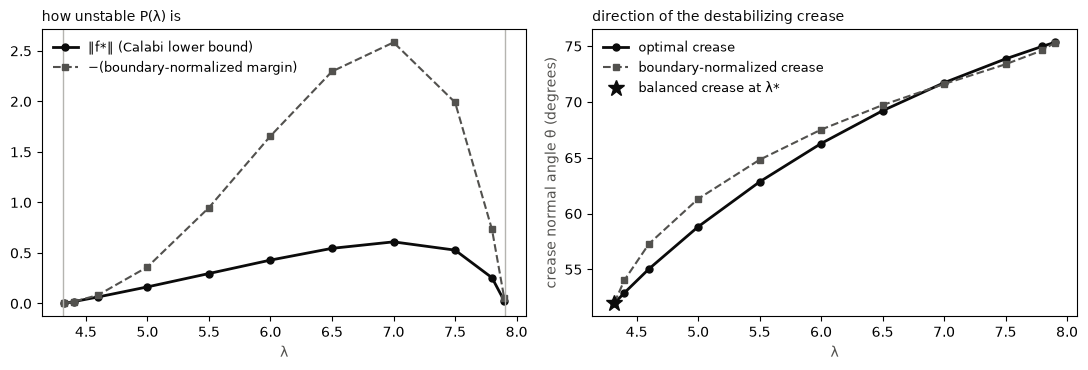

In [14]:
R = np.array(rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.plot(R[:, 0], R[:, 1], 'o-', color=viz.INK, lw=2, ms=5, label='‖f*‖ (Calabi lower bound)')
ax.plot(R[:, 0], -R[:, 3], 's--', color=viz.INK_2, lw=1.5, ms=5, label='−(boundary-normalized margin)')
for v in (LAM_STAR, LAM_2STAR):
    ax.axvline(v, color='#b5b4b0', lw=1)
ax.set_xlabel('λ', color=viz.INK_2); ax.legend(frameon=False, fontsize=9)
ax.set_title('how unstable P(λ) is', loc='left', fontsize=10, color=viz.INK)
ax = axes[1]
ax.plot(R[:, 0], R[:, 2], 'o-', color=viz.INK, lw=2, ms=5, label='optimal crease')
ax.plot(R[:, 0], R[:, 4], 's--', color=viz.INK_2, lw=1.5, ms=5, label='boundary-normalized crease')
ax.plot([LAM_STAR], [THETA_STAR], '*', color=viz.INK, ms=12, label='balanced crease at λ*')
ax.set_xlabel('λ', color=viz.INK_2); ax.set_ylabel('crease normal angle θ (degrees)', color=viz.INK_2)
ax.legend(frameon=False, fontsize=9)
ax.set_title('direction of the destabilizing crease', loc='left', fontsize=10, color=viz.INK)
fig.tight_layout()

**Reading the family.** ‖f*‖ vanishes at both ends of the unstable window and is largest in between; both creases tend to the balanced crease at λ* (the star), where both normalizations see the same zero. In between they differ by a few degrees.

**What this says about the numerics of §§3–5.** If the limit really decomposes, a minimizing sequence on Q_12 looks like u_∞ + t·f* with t → ∞ and the two pieces decouple, each solving its own extremal problem with a complete end at the crease (zero boundary measure: the inverse Hessian vanishes to second order there). A global polynomial cannot represent a growing kink along a line, which is one reason the degree-d solutions above do not converge. A solver adapted to this would work on the pieces separately, with a new singular term at the crease edge; whether extremal metrics exist on the pieces is the question studied by Apostolov–Auvray–Sektnan (arXiv:1711.08424).

## What this shows, and what it doesn't

- **Robust.** On the stable orbifold everything converges and curvature stays bounded. On the unstable one there is no convergence under refinement, and the best degree-d metrics degenerate along two specific edges, above all e3 (and e1): the metrics on those divisors collapse, and |Ric|² grows by many orders of magnitude in a layer along them (about distance⁻⁴ along the line into e3). The largest curvature is at the edges, consistent with Weber's classification ruling out interior blow-up; the interior values are far smaller, though not small.
- **Not robust.** The values of F_min and of the curvature in the unstable case depend on how finely convexity is enforced near the edges.
- **Open.** The destabilizing crease cuts off the corner between e1 and e2. One of the degenerating divisors, e1, is in that corner; the other, e3, is the opposite edge, and e2 hardly degenerates. How the degenerating divisors relate to the crease, if at all, is not clear from these computations. (An earlier version of this notebook suggested that the potential escapes along the crease; that came from enforcing convexity too sparsely and is withdrawn.)